# Kondycja finansowa a bankructwo w ciągu roku
### Analiza 13 wskaźników przedsiębiorstw

**Pytanie badawcze:** czym różnią się wyniki finansowe firm, które zbankrutowały w ciągu kolejnego roku, od wyników pozostałych firm?

Przedmiotem analizy są **X1, X2, X3, X5, X6, X24, X29, X34, X35, X46, X56, X58 i X62**. Obejmują rentowność, płynność, zadłużenie, historię wyników, koszty i wielkość przedsiębiorstwa.

Etykieta `class = 1` oznacza bankructwo w rocznym horyzoncie po obserwacji danych, a `class = 0` — brak bankructwa w tym okresie. Brak bankructwa nie jest równoznaczny z dobrą kondycją finansową. Analizujemy rekordy sprawozdań; bez identyfikatorów nie potwierdzamy, że każdy rekord dotyczy innej firmy.

Cztery wykresy i kilka tabel prowadzą od obrazu próby do współwystępowania sygnałów trudności. Wyniki opisują zależności, ale nie ustalają przyczyn bankructwa.

Źródło: [UCI — Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data), część `5year.arff`. Jej etykieta dotyczy bankructwa **za jeden rok**. Dane odczytujemy z lokalnego pliku `dane_do_analizy.xlsx`.

## 1. Co oznaczają analizowane wskaźniki?

| Wskaźnik | Definicja | Jak go czytać? |
|:--|:--|:--|
| **X1 — rentowność aktywów netto** | Zysk netto / aktywa ogółem | 0,05 oznacza zysk równy 5% aktywów. Wynik ujemny oznacza stratę. |
| **X2 — zadłużenie ogólne** | Zobowiązania ogółem / aktywa ogółem | Skala zobowiązań wobec majątku. Wynik powyżej 1 oznacza zobowiązania większe od aktywów i jest ekonomicznie możliwy. |
| **X3 — kapitał obrotowy do aktywów** | (Aktywa obrotowe − zobowiązania krótkoterminowe) / aktywa ogółem | Ujemny wynik oznacza niedobór aktywów obrotowych względem bieżącego długu. |
| **X5 — bufor płynności wobec kosztów** | 365 × (gotówka + krótkoterminowe papiery wartościowe + należności − zobowiązania krótkoterminowe) / (koszty operacyjne − amortyzacja) | Bufor płynnych składników wobec kosztów ze wzoru UCI. Znak zależy też od mianownika; to nie dosłowny czas do utraty gotówki. |
| **X6 — wynik zatrzymany do aktywów** | Wynik zatrzymany / aktywa ogółem | Akumulacja wyników pozostawionych w firmie wobec majątku. Nie jest bieżącym stanem gotówki. |
| **X24 — wynik brutto z trzech lat do aktywów** | Zysk brutto z trzech lat / aktywa ogółem, według UCI | Dłuższa perspektywa wyników; nie traktujemy jej jako średniorocznej stopy zysku. |
| **X29 — wielkość przedsiębiorstwa** | Logarytm aktywów ogółem | Większy wynik oznacza większe aktywa. Bez podstawy logarytmu i jednostki aktywów nie przeliczamy na kwoty. |
| **X34 — koszty operacyjne do zobowiązań** | Koszty operacyjne / zobowiązania ogółem | Wzrost może oznaczać większe koszty albo mniejsze zobowiązania; nie ma jednej automatycznie korzystnej interpretacji. |
| **X35 — rentowność majątku na poziomie sprzedaży** | Wynik na sprzedaży / aktywa ogółem | Wynik podstawowej działalności sprzedażowej wobec majątku; inny poziom wyniku niż zysk netto. |
| **X46 — płynność szybka** | (Aktywa obrotowe − zapasy) / zobowiązania krótkoterminowe | Pokrycie bieżącego długu aktywami obrotowymi bez zapasów. Wynik 1 nie gwarantuje zdolności płatniczej. |
| **X56 — marża po wskazanych kosztach sprzedaży** | (Sprzedaż − koszt sprzedanych produktów) / sprzedaż | Część sprzedaży pozostająca po wskazanych kosztach. Nie jest to marża netto. |
| **X58 — kosztochłonność sprzedaży** | Koszty ogółem / sprzedaż ogółem | Wynik powyżej 1 oznacza przewagę kosztów nad sprzedażą. |
| **X62 — zobowiązania krótkoterminowe wobec sprzedaży** | 365 × zobowiązania krótkoterminowe / sprzedaż | Skala bieżącego długu wobec dziennej sprzedaży. Nie jest dokładnym terminem płatności. |

X1, X2, X3, X6, X24 i X35 prezentujemy w **procentach aktywów**, X56 i X58 w **procentach sprzedaży**. X34 i X46 są ilorazami. Zapis 0,05 i 5% oznacza ten sam poziom; zmieniamy tylko prezentację.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from IPython.display import display, Markdown

DATA=Path('dane_do_analizy.xlsx')
if not DATA.exists():DATA=Path('C:/Users/jakub/Desktop/Analiza_bankructwa_5year/dane_do_analizy.xlsx')
FEATURES=['X1','X2','X3','X5','X6','X24','X29','X34','X35','X46','X56','X58','X62']
source_hash=hashlib.sha256(DATA.read_bytes()).hexdigest()
df=pd.read_excel(DATA,sheet_name='Dane_czyste_z_brakami',usecols=FEATURES+['class'])[FEATURES+['class']]
assert set(df['class'].unique())=={0,1}
assert not np.isinf(df[FEATURES]).any().any()
NAMES={'X1':'Rentowność netto','X2':'Zadłużenie ogólne','X3':'Kapitał obrotowy','X5':'Bufor płynności','X6':'Wynik zatrzymany','X24':'Wynik z trzech lat','X29':'Wielkość firmy','X34':'Koszty / zobowiązania','X35':'Rentowność na sprzedaży','X46':'Płynność szybka','X56':'Marża sprzedaży','X58':'Koszty / sprzedaż','X62':'Dług / sprzedaż'}
UNITS={'X1':('% aktywów',100),'X2':('% aktywów',100),'X3':('% aktywów',100),'X5':('wg wzoru UCI',1),'X6':('% aktywów',100),'X24':('% aktywów',100),'X29':('log aktywów',1),'X34':('razy',1),'X35':('% aktywów',100),'X46':('razy',1),'X56':('% sprzedaży',100),'X58':('% sprzedaży',100),'X62':('dni wg wzoru',1)}
BLUE,RED,INK='#28799A','#D76A50','#17324D'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.facecolor':'white','axes.facecolor':'#FAFCFD','axes.labelcolor':INK,'axes.titleweight':'bold','axes.titlesize':13,'axes.spines.top':False,'axes.spines.right':False,'grid.color':'#DDE5EB','savefig.dpi':160})
def pl(v,digits=2):return f'{v:,.{digits}f}'.replace(',',' ').replace('.',',')
def table(frame):
    display(frame.style.hide(axis='index').set_table_styles([
      {'selector':'th','props':[('background','#17324D'),('color','white'),('padding','9px 11px'),('text-align','left')]},
      {'selector':'td','props':[('padding','8px 11px'),('border-bottom','1px solid #e3eaf0'),('text-align','left')]},
      {'selector':'table','props':[('border-collapse','collapse'),('font-family','Arial, sans-serif'),('font-size','13px')]}
    ]))
counts=df['class'].value_counts().sort_index()
table(pd.DataFrame({'Grupa':['Bez bankructwa','Bankructwo w ciągu roku'],'Liczba rekordów':[int(counts[0]),int(counts[1])],'Udział':[pl(counts[0]/len(df)*100)+'%',pl(counts[1]/len(df)*100)+'%']}))
display(Markdown(f'**Wniosek.** Bankructwa stanowią **{pl(counts[1]/len(df)*100)}%** próby. Sama liczba firm w każdej grupie nie pokazuje różnic finansowych, bo grupa bez bankructwa jest wielokrotnie większa. Dlatego dalej porównujemy mediany, kwartyle i odsetki wewnątrz grup. Są to częstości w badanym zbiorze, a nie szacunek częstości bankructwa wszystkich polskich przedsiębiorstw.'))

Grupa,Liczba rekordów,Udział
Bez bankructwa,5438,"93,02%"
Bankructwo w ciągu roku,408,"6,98%"


**Wniosek.** Bankructwa stanowią **6,98%** próby. Sama liczba firm w każdej grupie nie pokazuje różnic finansowych, bo grupa bez bankructwa jest wielokrotnie większa. Dlatego dalej porównujemy mediany, kwartyle i odsetki wewnątrz grup. Są to częstości w badanym zbiorze, a nie szacunek częstości bankructwa wszystkich polskich przedsiębiorstw.

## 2. Na ilu obserwacjach opieramy obliczenia?

Pusta wartość oznacza, że wyniku nie znamy — nie jest zerem. Statystykę liczymy z dostępnych wartości danego wskaźnika. Brak w jednej kolumnie nie wyklucza firmy z pozostałych obliczeń. Poniższa tabela pokazuje wskaźniki z co najmniej pięcioma brakami. Dokładne liczby dostępnych wyników obu grup znajdują się w części 4.

In [2]:
availability=[]
for c in FEATURES:
    total=int(df[c].isna().sum())
    if total>=5:
        n0=int(df.loc[df['class']==0,c].isna().sum());n1=int(df.loc[df['class']==1,c].isna().sum())
        availability.append({'Wskaźnik':c,'Braki ogółem':total,'Udział braków':pl(total/len(df)*100)+'%','Bez bankructwa':f'{n0} ({pl(n0/counts[0]*100)}%)','Bankructwo':f'{n1} ({pl(n1/counts[1]*100)}%)'})
table(pd.DataFrame(availability))
c=df[FEATURES].isna().mean().idxmax()
display(Markdown(f'**Wniosek.** Największy udział braków w analizowanym zestawie ma **{c}: {pl(df[c].isna().mean()*100)}%**. Większość porównań obejmuje niemal całą próbę. Dla X34 dostępne są **{df.X34.notna().sum()}** obserwacje. Różnica udziału braków między grupami nie oznacza sama w sobie określonego wyniku finansowego; może wynikać z dostępności danych lub konstrukcji ilorazu. Nie zastępujemy braku liczbą, którą przedstawialibyśmy jako rzeczywisty pomiar.'))

Wskaźnik,Braki ogółem,Udział braków,Bez bankructwa,Bankructwo
X5,11,"0,19%","11 (0,20%)","0 (0,00%)"
X24,133,"2,28%","132 (2,43%)","1 (0,25%)"
X34,14,"0,24%","11 (0,20%)","3 (0,74%)"
X46,24,"0,41%","18 (0,33%)","6 (1,47%)"
X58,5,"0,09%","5 (0,09%)","0 (0,00%)"


**Wniosek.** Największy udział braków w analizowanym zestawie ma **X24: 2,28%**. Większość porównań obejmuje niemal całą próbę. Dla X34 dostępne są **5832** obserwacje. Różnica udziału braków między grupami nie oznacza sama w sobie określonego wyniku finansowego; może wynikać z dostępności danych lub konstrukcji ilorazu. Nie zastępujemy braku liczbą, którą przedstawialibyśmy jako rzeczywisty pomiar.

## 3. Średnia a wynik typowej firmy

Ilorazy finansowe mogą osiągać bardzo duże wartości, np. przy małym mianowniku. **Średnia** uwzględnia rozmiar każdej obserwacji, a **mediana** wskazuje wynik środkowy. Potrzebujemy obu perspektyw.

Średnia dla środkowych 98% wyników jest wyłącznie sprawdzeniem wrażliwości na ogony rozkładu. Nie zmieniamy danych; wszystkie dalsze obliczenia nadal wykorzystują dostępne obserwacje.

In [3]:
rows=[]
for c in ['X1','X34','X62']:
    unit,factor=UNITS[c];s=df[c].dropna();lo,hi=s.quantile([.01,.99])
    rows.append({'Wskaźnik':c,'Jednostka':unit,'Średnia':pl(s.mean()*factor),'Mediana':pl(s.median()*factor),'Średnia w środkowych 98%':pl(s[s.between(lo,hi)].mean()*factor)})
table(pd.DataFrame(rows))
display(Markdown(f'**Wniosek.** Dla X1 średnia wynosi **{pl(df.X1.mean()*100)}%**, mimo dodatniej mediany **{pl(df.X1.median()*100)}%**. Nieliczne duże straty mogą więc zmienić znak średniej całej próby; nie wynika z tego, że większość firm ma stratę. W X34 i X62 duże dodatnie wartości przesuwają średnią w górę. To uzasadnia opis typowej sytuacji medianą i kwartylami. Sama skrajność nie dowodzi błędu ani nie wskazuje jednej przyczyny ekonomicznej.'))

Wskaźnik,Jednostka,Średnia,Mediana,Średnia w środkowych 98%
X1,% aktywów,"-2,34","4,67","5,33"
X34,razy,"5,04","1,72","2,93"
X62,dni wg wzoru,"243,79","73,86","97,83"


**Wniosek.** Dla X1 średnia wynosi **-2,34%**, mimo dodatniej mediany **4,67%**. Nieliczne duże straty mogą więc zmienić znak średniej całej próby; nie wynika z tego, że większość firm ma stratę. W X34 i X62 duże dodatnie wartości przesuwają średnią w górę. To uzasadnia opis typowej sytuacji medianą i kwartylami. Sama skrajność nie dowodzi błędu ani nie wskazuje jednej przyczyny ekonomicznej.

## 4. Profil finansowy obu grup

Przedział **Q1–Q3** obejmuje środkowe 50% wyników i pokazuje zróżnicowanie niewidoczne w samej medianie. W każdej komórce podajemy **medianę [Q1; Q3]**. Kolumna `n: 0 / 1` oznacza liczby dostępnych wyników odpowiednio bez bankructwa i przy bankructwie. Jednostka jest wspólna dla całego wiersza.

In [4]:
profile=[]
for c in FEATURES:
    unit,f=UNITS[c];a=df.loc[df['class']==0,c].dropna()*f;b=df.loc[df['class']==1,c].dropna()*f
    def desc(s):return pl(s.median())+' ['+pl(s.quantile(.25))+'; '+pl(s.quantile(.75))+']'
    profile.append({'Wskaźnik':c,'Jednostka':unit,'Bez bankructwa':desc(a),'Bankructwo':desc(b),'n: 0 / 1':f'{len(a)} / {len(b)}'})
table(pd.DataFrame(profile))
display(Markdown(f'**Wniosek: rentowność i koszty.** Ujemne mediany X1, X35 i X24 w grupie bankructw tworzą spójny obraz słabszego generowania wyniku na kilku poziomach, a nie tylko w jednej pozycji. Mediana X58 wynosi tam **{pl(df.loc[df["class"]==1,"X58"].median()*100)}%**, wobec **{pl(df.loc[df["class"]==0,"X58"].median()*100)}%** bez bankructwa. Typowy rekord w grupie bankructw ma koszty przekraczające sprzedaż; nie oznacza to takiego wyniku u każdej firmy.'))
display(Markdown(f'**Wniosek: finansowanie i płynność.** Mediana X46 to **{pl(df.loc[df["class"]==1,"X46"].median())}** przy bankructwie i **{pl(df.loc[df["class"]==0,"X46"].median())}** w drugiej grupie. Niższy bufor aktywów obrotowych bez zapasów współwystępuje z wyższymi X2 i X62, czyli większym długiem względem majątku i sprzedaży. Bez harmonogramów płatności oraz przepływów pieniężnych nie ustalamy rzeczywistego momentu utraty płynności.'))
display(Markdown('**Wniosek: historia i rozmiar.** Mediana X6 jest ujemna przy bankructwie, a w pozostałej grupie wynosi zero. Sugeruje to słabszą historię akumulacji wyników; zero nie oznacza jednak braku gotówki. Niższy X29 wskazuje na mniejsze aktywa w grupie bankructw w tej próbie. Bez informacji o branży i strukturze firm nie możemy stwierdzić, że sam rozmiar chroni przed bankructwem.'))

Wskaźnik,Jednostka,Bez bankructwa,Bankructwo,n: 0 / 1
X1,% aktywów,"5,18 [0,73; 12,08]","-6,70 [-23,29; 2,36]",5438 / 407
X2,% aktywów,"43,61 [25,08; 64,31]","72,48 [47,83; 97,68]",5437 / 407
X3,% aktywów,"23,26 [6,25; 42,68]","-1,31 [-30,35; 23,88]",5438 / 407
X5,wg wzoru UCI,"3,54 [-39,20; 51,55]","-56,71 [-133,11; -0,71]",5427 / 408
X6,% aktywów,"0,00 [0,00; 12,40]","-1,18 [-29,12; 0,00]",5438 / 407
X24,% aktywów,"17,66 [3,83; 36,77]","-4,69 [-29,14; 13,29]",5306 / 407
X29,log aktywów,"4,19 [3,68; 4,69]","3,74 [3,03; 4,26]",5438 / 407
X34,razy,"1,72 [0,25; 4,08]","1,71 [0,28; 3,54]",5427 / 405
X35,% aktywów,"6,61 [1,22; 14,16]","-6,90 [-23,90; 3,83]",5438 / 407
X46,razy,"1,12 [0,68; 2,03]","0,47 [0,21; 0,85]",5420 / 402


**Wniosek: rentowność i koszty.** Ujemne mediany X1, X35 i X24 w grupie bankructw tworzą spójny obraz słabszego generowania wyniku na kilku poziomach, a nie tylko w jednej pozycji. Mediana X58 wynosi tam **100,79%**, wobec **94,69%** bez bankructwa. Typowy rekord w grupie bankructw ma koszty przekraczające sprzedaż; nie oznacza to takiego wyniku u każdej firmy.

**Wniosek: finansowanie i płynność.** Mediana X46 to **0,47** przy bankructwie i **1,12** w drugiej grupie. Niższy bufor aktywów obrotowych bez zapasów współwystępuje z wyższymi X2 i X62, czyli większym długiem względem majątku i sprzedaży. Bez harmonogramów płatności oraz przepływów pieniężnych nie ustalamy rzeczywistego momentu utraty płynności.

**Wniosek: historia i rozmiar.** Mediana X6 jest ujemna przy bankructwie, a w pozostałej grupie wynosi zero. Sugeruje to słabszą historię akumulacji wyników; zero nie oznacza jednak braku gotówki. Niższy X29 wskazuje na mniejsze aktywa w grupie bankructw w tej próbie. Bez informacji o branży i strukturze firm nie możemy stwierdzić, że sam rozmiar chroni przed bankructwem.

## 5. Rozkłady rentowności i zadłużenia

Na wykresie pudełkowym kreska to mediana, pudełko obejmuje środkowe 50% wyników, a wąsy sięgają do skrajnych obserwacji w granicy 1,5 rozstępu międzykwartylowego od pudełka. Punkty poza wąsami są ukryte dla czytelności, lecz **wszystkie wartości uczestniczą w obliczeniu kwartylów**. Linie przerywane oznaczają zero zysku oraz zobowiązania równe aktywom.

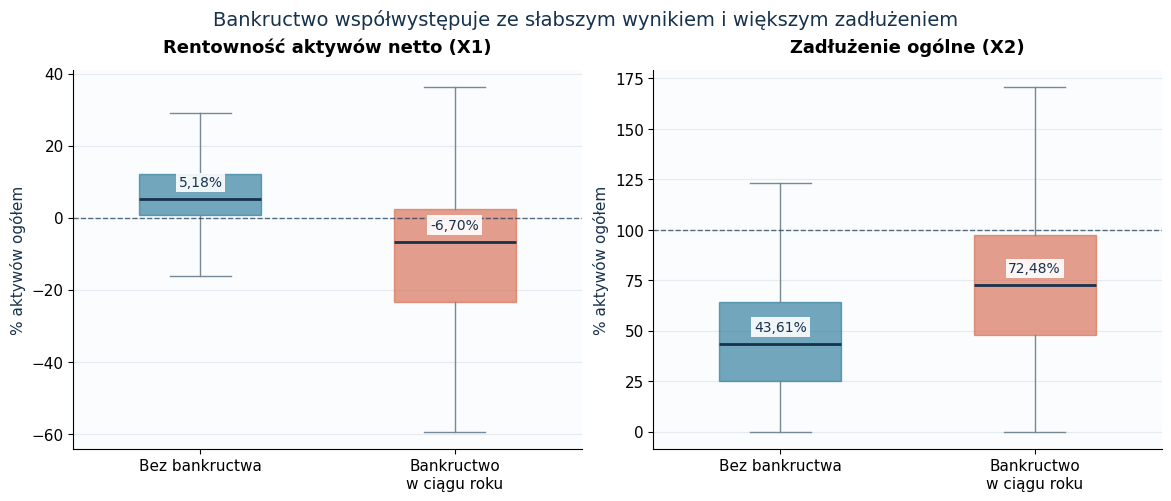

**Interpretacja.** Stratę netto wykazuje **62,7%** rekordów bankructw z dostępnym X1 i **17,8%** drugiej grupy. Strata utrudnia odbudowę kapitału z bieżących wyników, a większe zadłużenie zwiększa obciążenie majątku zobowiązaniami. Rozkłady nadal się nakładają: sam wskaźnik nie oddziela wszystkich bankructw. Dodatni zysk nie gwarantuje spłaty długu, a pojedyncza strata nie przesądza o bankructwie.

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11.6,4.9),layout='constrained')
for ax,c,title,threshold in zip(axes,['X1','X2'],['Rentowność aktywów netto (X1)','Zadłużenie ogólne (X2)'],[0,100]):
    vals=[df.loc[df['class']==g,c].dropna().to_numpy()*100 for g in [0,1]]
    bp=ax.boxplot(vals,patch_artist=True,showfliers=False,widths=.48,medianprops={'color':INK,'linewidth':2},whiskerprops={'color':'#778996'},capprops={'color':'#778996'})
    for box,color in zip(bp['boxes'],[BLUE,RED]):box.set(facecolor=color,alpha=.65,edgecolor=color)
    ax.set_xticks([1,2],['Bez bankructwa','Bankructwo'+chr(10)+'w ciągu roku'])
    ax.set_title(title,pad=13);ax.set_ylabel('% aktywów ogółem')
    ax.axhline(threshold,color=INK,linestyle='--',linewidth=1,alpha=.7)
    ax.grid(axis='y',alpha=.7);ax.set_axisbelow(True)
    for pos,v in enumerate(vals,1):
        ax.annotate(pl(np.median(v))+'%',(pos,np.median(v)),xytext=(0,7),textcoords='offset points',fontsize=10,color=INK,va='bottom',ha='center',bbox={'facecolor':'white','alpha':.9,'edgecolor':'none','pad':2})
fig.suptitle('Bankructwo współwystępuje ze słabszym wynikiem i większym zadłużeniem',fontsize=14,color=INK)
plt.show()
a=df.loc[df['class']==0,'X1'].dropna();b=df.loc[df['class']==1,'X1'].dropna()
display(Markdown(f'**Interpretacja.** Stratę netto wykazuje **{pl((b<0).mean()*100,1)}%** rekordów bankructw z dostępnym X1 i **{pl((a<0).mean()*100,1)}%** drugiej grupy. Strata utrudnia odbudowę kapitału z bieżących wyników, a większe zadłużenie zwiększa obciążenie majątku zobowiązaniami. Rozkłady nadal się nakładają: sam wskaźnik nie oddziela wszystkich bankructw. Dodatni zysk nie gwarantuje spłaty długu, a pojedyncza strata nie przesądza o bankructwie.'))

## 6. Siła różnic — niezależnie od jednostki

Nie można bezpośrednio porównać różnicy w procentach z różnicą w dniach. Używamy więc **efektu rangowego Cliffa**, o zakresie od −1 do +1:

- ujemny: wyniki są częściej mniejsze w grupie bankructw;
- dodatni: częściej większe w grupie bankructw;
- bliski zeru: brak wyraźnej przewagi jednej grupy w uporządkowaniu wartości.

Kolor oznacza kierunek różnicy, a nie ocenę „dobrze/źle”. To nie jest ważność cechy w modelu ani korelacja z etykietą. Wynik bliski zeru nie wyklucza różnic w ogonach lub zależności nieliniowych.

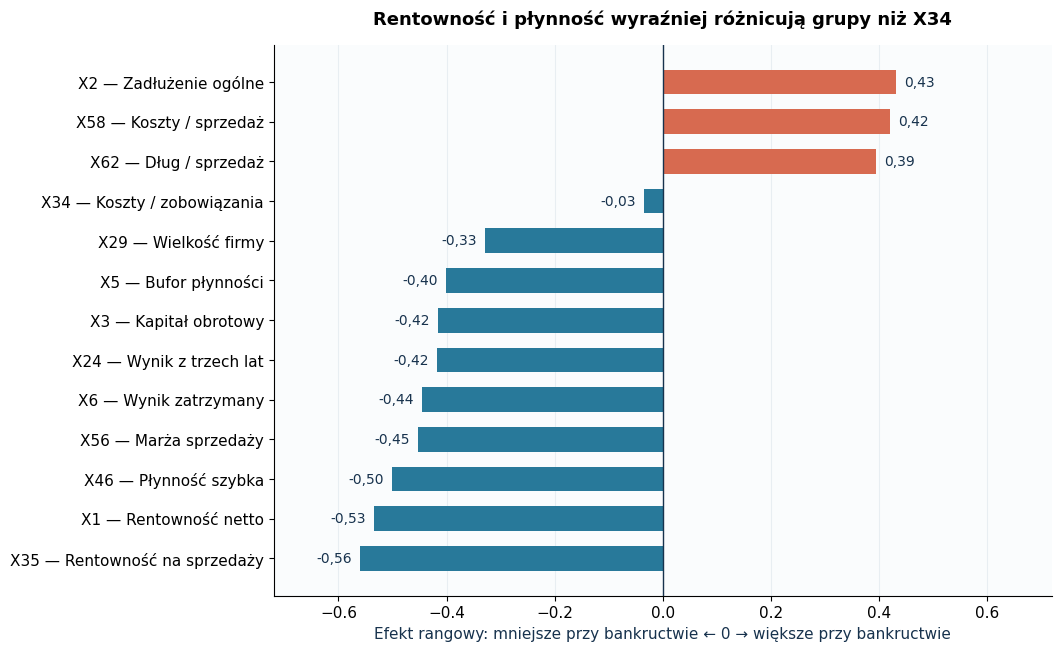

**Interpretacja.** X35 i X1 pokazują duże różnice rentowności, a X46 różnicę płynności. Efekt X35 wynosi **-0,56**. Odpowiada to około **78,0%** prawdopodobieństwa, że losowo zestawiony wynik firmy z bankructwem będzie niższy od wyniku firmy bez bankructwa, z połową remisów zaliczoną do tej miary. To opis rozdzielenia wyników w próbie, nie prawdopodobieństwo bankructwa konkretnej firmy. X34 jest blisko zera i samym kierunkiem wartości nie odróżnia grup równie wyraźnie.

In [6]:
effects=[]
for c in FEATURES:
    a=df.loc[df['class']==0,c].dropna();b=df.loc[df['class']==1,c].dropna()
    delta=2*mannwhitneyu(b,a,alternative='two-sided').statistic/(len(a)*len(b))-1
    effects.append({'Wskaźnik':c,'Delta':float(delta)})
effect=pd.DataFrame(effects).set_index('Wskaźnik');ordered=effect.sort_values('Delta')
fig,ax=plt.subplots(figsize=(10.5,6.4),layout='constrained')
vals=ordered.Delta.to_numpy();ys=np.arange(len(ordered))
ax.barh(ys,vals,color=[BLUE if v<0 else RED for v in vals],height=.62)
ax.set_yticks(ys,[c+' — '+NAMES[c] for c in ordered.index])
for j,v in enumerate(vals):ax.text(v+(.015 if v>=0 else -.015),j,pl(v,2),ha='left' if v>=0 else 'right',va='center',fontsize=10,color=INK)
ax.axvline(0,color=INK,linewidth=1);ax.set_xlim(-.72,.72)
ax.set_xlabel('Efekt rangowy: mniejsze przy bankructwie ← 0 → większe przy bankructwie')
ax.set_title('Rentowność i płynność wyraźniej różnicują grupy niż X34',pad=15)
ax.grid(axis='x',alpha=.6);ax.set_axisbelow(True)
plt.show()
prob=(1-effect.loc['X35','Delta'])/2*100
display(Markdown(f'**Interpretacja.** X35 i X1 pokazują duże różnice rentowności, a X46 różnicę płynności. Efekt X35 wynosi **{pl(effect.loc["X35","Delta"],2)}**. Odpowiada to około **{pl(prob,1)}%** prawdopodobieństwa, że losowo zestawiony wynik firmy z bankructwem będzie niższy od wyniku firmy bez bankructwa, z połową remisów zaliczoną do tej miary. To opis rozdzielenia wyników w próbie, nie prawdopodobieństwo bankructwa konkretnej firmy. X34 jest blisko zera i samym kierunkiem wartości nie odróżnia grup równie wyraźnie.'))

## 7. X34: co oznaczają podobne wyniki?

X34 odnosi koszty operacyjne do zobowiązań. Nie mierzy bezpośrednio marży ani pokrycia odsetek. Wzrost kosztów i spadek zobowiązań zwiększają ten iloraz, mimo różnego znaczenia ekonomicznego.

In [7]:
a=df.loc[df['class']==0,'X34'].dropna();b=df.loc[df['class']==1,'X34'].dropna()
display(Markdown(f'**Wniosek.** Mediany X34 wynoszą **{pl(a.median(),3)} i {pl(b.median(),3)}**, a środkowe zakresy odpowiednio **{pl(a.quantile(.25),3)}–{pl(a.quantile(.75),3)}** oraz **{pl(b.quantile(.25),3)}–{pl(b.quantile(.75),3)}**. Efekt rangowy **{pl(effect.loc["X34","Delta"],3)}** także wskazuje na słabą jednostronną różnicę. Nie ma podstaw, aby opisywać wyższe X34 jako prosty samodzielny sygnał bankructwa lub dobrej kondycji. Nie dowodzi to braku jakiejkolwiek informacji: znaczenie może zależeć od innych miar lub części rozkładu. Takich interakcji nie przypisujemy jednak bez osobnego sprawdzenia.'))

**Wniosek.** Mediany X34 wynoszą **1,721 i 1,706**, a środkowe zakresy odpowiednio **0,250–4,079** oraz **0,279–3,536**. Efekt rangowy **-0,034** także wskazuje na słabą jednostronną różnicę. Nie ma podstaw, aby opisywać wyższe X34 jako prosty samodzielny sygnał bankructwa lub dobrej kondycji. Nie dowodzi to braku jakiejkolwiek informacji: znaczenie może zależeć od innych miar lub części rozkładu. Takich interakcji nie przypisujemy jednak bez osobnego sprawdzenia.

## 8. Współwystępowanie straty i niedoboru kapitału obrotowego

Tworzymy cztery grupy według warunków **straty netto (X1 < 0)** i **ujemnego kapitału obrotowego (X3 < 0)**. Progi wynikają z definicji finansowej, a nie z optymalizacji modelu.

Słupek pokazuje odsetek bankructw **wewnątrz grupy**. Pod procentem podano liczbę bankructw / liczbę rekordów. Odcinki to 95% przedziały Wilsona dla udziału przy założeniu niezależnych obserwacji. Nie obejmują błędów danych, zależności między sprawozdaniami ani niereprezentatywności próby.

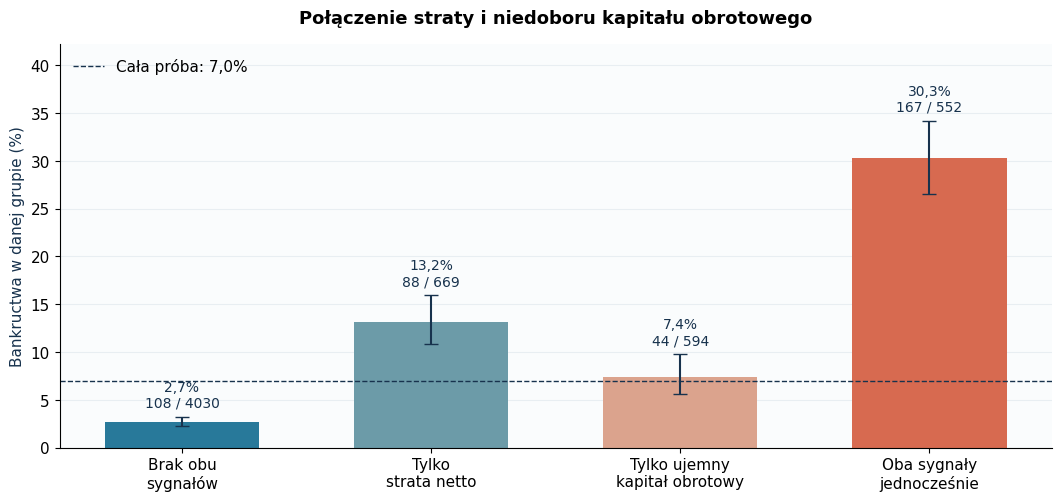

**Interpretacja.** Przy obu sygnałach udział bankructw wynosi **30,3%**, wobec **2,7%** przy braku obu — około **11,3 razy** więcej. Strata ogranicza odbudowę finansowania z wyniku, a ujemny kapitał obrotowy oznacza mniejszy bufor wobec bieżących zobowiązań. Połączenie jest więc spójne z większą podatnością na trudności, lecz nie jest dowodem przyczynowym. Nawet przy obu sygnałach większość rekordów nie kończy się bankructwem; brak obu również nie oznacza zerowego zagrożenia. Liczba rekordów pominiętych wyłącznie w tym porównaniu z powodu braku X1 lub X3: **1**.

In [8]:
valid=df.dropna(subset=['X1','X3']).copy()
loss=valid.X1<0;shortage=valid.X3<0
valid['grupa']=np.select([~loss&~shortage,loss&~shortage,~loss&shortage,loss&shortage],[0,1,2,3],default=-1)
groups=valid.groupby('grupa')['class'].agg(n='size',bankructwa='sum').reindex(range(4));groups['p']=groups.bankructwa/groups.n
z=1.959963984540054;p0=groups.p.to_numpy();ns=groups.n.to_numpy()
center=(p0+z*z/(2*ns))/(1+z*z/ns);half=z*np.sqrt(p0*(1-p0)/ns+z*z/(4*ns*ns))/(1+z*z/ns)
groups['dol']=center-half;groups['gora']=center+half
fig,ax=plt.subplots(figsize=(10.5,4.9),layout='constrained')
nl=chr(10)
labels=['Brak obu'+nl+'sygnałów','Tylko'+nl+'strata netto','Tylko ujemny'+nl+'kapitał obrotowy','Oba sygnały'+nl+'jednocześnie']
ax.bar(range(4),p0*100,color=[BLUE,'#6C9BA8','#DBA38D',RED],width=.62)
ax.errorbar(range(4),p0*100,yerr=np.vstack([p0-groups.dol,groups.gora-p0])*100,fmt='none',ecolor=INK,capsize=5)
for j,row in groups.iterrows():ax.text(j,row.gora*100+1,pl(row.p*100,1)+'%'+nl+str(int(row.bankructwa))+' / '+str(int(row.n)),ha='center',fontsize=10,color=INK)
ax.axhline(df['class'].mean()*100,color=INK,linestyle='--',linewidth=1,label='Cała próba: '+pl(df['class'].mean()*100,1)+'%')
ax.set_xticks(range(4),labels);ax.set_ylabel('Bankructwa w danej grupie (%)')
ax.set_ylim(0,groups.gora.max()*100+8);ax.set_title('Połączenie straty i niedoboru kapitału obrotowego',pad=15)
ax.grid(axis='y',alpha=.6);ax.set_axisbelow(True);ax.legend(frameon=False,loc='upper left')
plt.show()
ratio=groups.loc[3,'p']/groups.loc[0,'p']
display(Markdown(f'**Interpretacja.** Przy obu sygnałach udział bankructw wynosi **{pl(groups.loc[3,"p"]*100,1)}%**, wobec **{pl(groups.loc[0,"p"]*100,1)}%** przy braku obu — około **{pl(ratio,1)} razy** więcej. Strata ogranicza odbudowę finansowania z wyniku, a ujemny kapitał obrotowy oznacza mniejszy bufor wobec bieżących zobowiązań. Połączenie jest więc spójne z większą podatnością na trudności, lecz nie jest dowodem przyczynowym. Nawet przy obu sygnałach większość rekordów nie kończy się bankructwem; brak obu również nie oznacza zerowego zagrożenia. Liczba rekordów pominiętych wyłącznie w tym porównaniu z powodu braku X1 lub X3: **{len(df)-len(valid)}**.'))

## 9. Powiązania między wskaźnikami

Korelacja rang **Spearmana** sprawdza, czy większym wartościom jednej miary zwykle towarzyszą większe lub mniejsze wartości drugiej. Jest mniej zależna od rozmiaru pojedynczych skrajności niż Pearson. Wynik dodatni oznacza zgodny kierunek, ujemny — przeciwny, a zero — brak wyraźnej zależności monotonicznej.

Dla czytelności mapa pokazuje osiem miar z różnych obszarów, a obliczenia obejmują wszystkie pary analizowanych 13. Każdą parę liczymy na dostępnych dla niej obserwacjach. Silna korelacja nie dowodzi przyczynowości ani pełnej zamienności wskaźników.

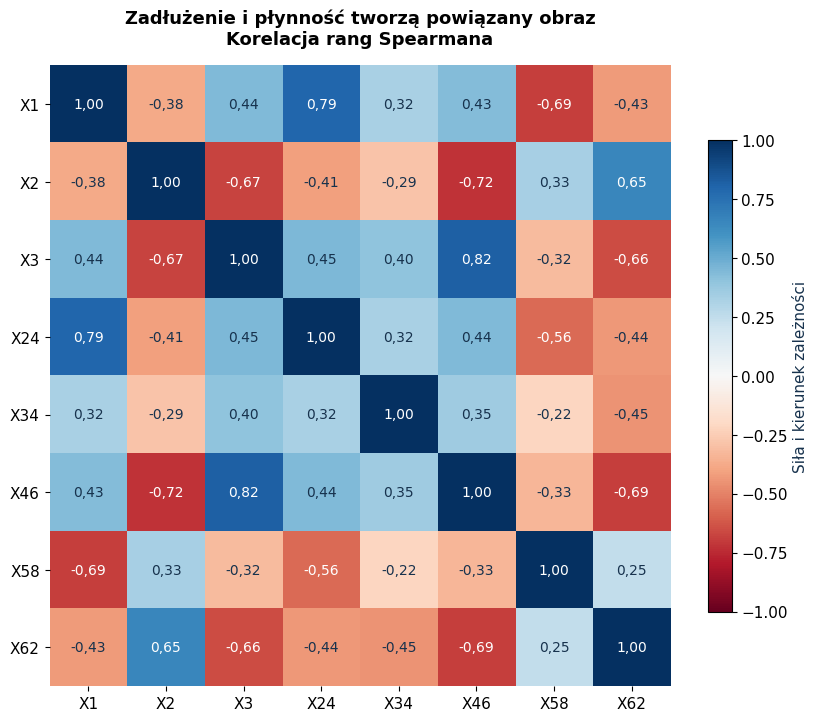

**Interpretacja.** X2 i X46 mają ujemną korelację **-0,72**: większemu obciążeniu majątku zobowiązaniami zwykle towarzyszy mniejszy bufor płynnych aktywów wobec długu krótkoterminowego. X3 i X46 są dodatnio powiązane (**0,82**), bo oba opisują finansowanie krótkoterminowe. Część zależności wynika ze wspólnych składników ilorazów — nie należy traktować kilku miar jako kilku niezależnych dowodów.

**Uzupełnienie.** W pełnym analizowanym zestawie korelacja X5–X46 wynosi **0,89**, a X56–X58 **-0,91**. Pierwsza para opisuje pokrewne aspekty płynności, druga marżę i kosztochłonność. To wyjaśnia spójność obrazu finansowego i potrzebę ostrożności przy późniejszej interpretacji znaczenia pojedynczej cechy modelu.

In [9]:
corr=df[FEATURES].corr(method='spearman');shown=['X1','X2','X3','X24','X34','X46','X58','X62'];mat=corr.loc[shown,shown]
fig,ax=plt.subplots(figsize=(9.0,7.1),layout='constrained')
img=ax.imshow(mat.to_numpy(),vmin=-1,vmax=1,cmap='RdBu')
ax.set_xticks(range(len(shown)),shown);ax.set_yticks(range(len(shown)),shown)
for i in range(len(shown)):
    for j in range(len(shown)):
        v=mat.iloc[i,j];ax.text(j,i,pl(v,2),ha='center',va='center',color='white' if abs(v)>.55 else INK,fontsize=10)
ax.set_title('Zadłużenie i płynność tworzą powiązany obraz'+chr(10)+'Korelacja rang Spearmana',pad=15)
ax.spines[['top','right','bottom','left']].set_visible(False)
cb=fig.colorbar(img,ax=ax,shrink=.76);cb.set_label('Siła i kierunek zależności')
plt.show()
display(Markdown(f'**Interpretacja.** X2 i X46 mają ujemną korelację **{pl(corr.loc["X2","X46"])}**: większemu obciążeniu majątku zobowiązaniami zwykle towarzyszy mniejszy bufor płynnych aktywów wobec długu krótkoterminowego. X3 i X46 są dodatnio powiązane (**{pl(corr.loc["X3","X46"])}**), bo oba opisują finansowanie krótkoterminowe. Część zależności wynika ze wspólnych składników ilorazów — nie należy traktować kilku miar jako kilku niezależnych dowodów.'))
display(Markdown(f'**Uzupełnienie.** W pełnym analizowanym zestawie korelacja X5–X46 wynosi **{pl(corr.loc["X5","X46"])}**, a X56–X58 **{pl(corr.loc["X56","X58"])}**. Pierwsza para opisuje pokrewne aspekty płynności, druga marżę i kosztochłonność. To wyjaśnia spójność obrazu finansowego i potrzebę ostrożności przy późniejszej interpretacji znaczenia pojedynczej cechy modelu.'))

## 10. Najważniejsze wnioski

1. **Rentowność jest czytelnym obszarem różnic.** Ujemne mediany X1, X35 i X24 oraz większa kosztochłonność X58 w grupie bankructw wskazują na słabsze generowanie wyniku na kilku poziomach. Nie każda firma ze stratą bankrutuje.
2. **Płynność i zadłużenie uzupełniają obraz zysku.** Wyższe X2 i X62 oraz niższe X3 i X46 pokazują większe obciążenie zobowiązaniami i mniejszy bufor krótkoterminowy. Sam zysk nie wystarcza do oceny zdolności płatniczej.
3. **Historia wyników daje kontekst.** X6 i X24 pokazują szerszy obraz niż pojedynczy bieżący wynik. Ich interpretacja nie jest jednak tożsama z oceną dostępnej gotówki.
4. **Współwystępowanie sygnałów jest ważniejsze niż pojedynczy próg.** Strata i ujemny kapitał obrotowy wiążą się z dużo większą częstością bankructw niż brak obu. To zależność w próbie, nie gotowa reguła dla nowej firmy.
5. **X34 wymaga ostrożnego opisu.** Podobne mediany i mały efekt rangowy nie uzasadniają traktowania go jako prostego samodzielnego sygnału bankructwa. Wartość zależy zarówno od kosztów, jak i od zobowiązań.
6. **Mediany, kwartyle i rangi pomagają uniknąć uproszczeń.** Skrajności wpływają na średnie, a wspólne składniki formuł na korelacje. Obserwowana spójność nie oznacza niezależności wskaźników.

### Zakres interpretacji

Wyniki opisują tę próbę. Nie mamy branż, dat ani identyfikatorów firm, więc nie potwierdzamy niezależności sprawozdań i nie wyjaśniamy mechanizmu zmian w czasie. Przedziały Wilsona zakładają niezależność. UCI wskazuje ponadto różne okresy zbierania danych dla bankructw i pozostałych przedsiębiorstw.

Nie wyciągamy wniosków przyczynowych, nie przyjmujemy uniwersalnych norm dla każdej branży i nie traktujemy częstości bankructwa w próbie jako prognozy dla wszystkich firm. Analiza opisowa nie zastępuje późniejszej walidacji modelu na odpowiednio wydzielonych danych.

Źródło definicji i horyzontu: [UCI Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data).

In [10]:
# Notebook odczytuje dane i pokazuje obliczenia; nie zapisuje bazy.
assert hashlib.sha256(DATA.read_bytes()).hexdigest()==source_hash
print('Kontrola: dane niezmienione. Analiza obejmuje 13 wskaźników i '+str(len(df))+' rekordów.')

Kontrola: dane niezmienione. Analiza obejmuje 13 wskaźników i 5846 rekordów.
